# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nancy121205/flyrank/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

### How to read the action queue

The queue ranks content items for **human review**, not automatic updates. Higher-ranked items have a stronger combination of visibility, freshness risk, and search-position opportunity in the baseline. If the completed model pipeline is available, its combined model-and-baseline score is used instead.

Each item has reason codes explaining why it was flagged. These codes are screening signals, not proof that a page is bad or that a refresh will increase traffic.

* `stale_visible_page`: the page has not been updated recently and has meaningful impressions.
* `declining_with_demand`: the existing trend label is down while impressions remain.
* `thin_visible_page`: the page has relatively low word count and meaningful impressions.
* `page_one_decay_risk`: the page is currently near page one and is not new.
* `low_ctr_visible_page`: the page has impressions and a relatively low click-through rate.
* `low_engagement_visible_page`: engagement or scroll metrics suggest a closer review may be useful.
* `general_refresh_review`: no specific rule fired, so the page remains a general review candidate.

**Workflow:** review the highest-ranked items first, verify the page and its intent, choose an action only after editorial review, and record what was actually changed. The score helps organize attention; it does not make the decision.


In [4]:
from pathlib import Path

# Check the notebook directory and common Colab repository locations.
SEARCH_ROOTS = list(dict.fromkeys([
    Path.cwd(),
    *Path.cwd().parents,
    Path("/content"),
    Path("/content/flyrank"),
]))

def find_file(relative_path):
    for root in SEARCH_ROOTS:
        candidate = root / relative_path
        if candidate.exists() and candidate.is_file():
            return candidate
    return None

final_path = find_file("outputs/refresh_queue.csv")
baseline_path = find_file("data/processed/baseline_refresh_queue.csv")
raw_path = find_file("data/raw/content_refresh_anonymized.csv")

# If the CSV is not present locally, use the public starter dataset.
if raw_path is None:
    raw_path = (
        "https://raw.githubusercontent.com/flyrank-bih/"
        "flyrank-ml-internship-starter/main/"
        "data/raw/content_refresh_anonymized.csv"
    )

print("Notebook working directory:", Path.cwd())
print("Final queue found:", final_path is not None)
print("Baseline queue found:", baseline_path is not None)
print("Dataset location:", raw_path)

Notebook working directory: /content
Final queue found: False
Baseline queue found: False
Dataset location: https://raw.githubusercontent.com/flyrank-bih/flyrank-ml-internship-starter/main/data/raw/content_refresh_anonymized.csv


In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display



# Prefer the model + baseline queue if the pipeline has already run.
if final_path is not None:
    source = pd.read_csv(final_path)
    queue_source = "model_plus_baseline"
    print("Using final pipeline queue:", final_path)

elif baseline_path is not None:
    source = pd.read_csv(baseline_path)
    queue_source = "baseline"
    print("Using baseline pipeline queue:", baseline_path)

else:
    if raw_path is None:
        raise FileNotFoundError(
            "Could not find the final queue, baseline queue, or starter CSV. "
            "Run this notebook from your repository or check the data path."
        )

    raw = pd.read_csv(raw_path)
    print("Building a transparent baseline from:", raw_path)

    required = {
        "content_id", "impressions_90d", "content_age_days",
        "days_since_last_update", "avg_position", "word_count",
        "sessions_90d", "ctr", "engagement_rate", "scroll_rate",
        "trend_direction"
    }
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"Required columns are missing: {sorted(missing)}")

    # Apply the starter pipeline's basic eligibility filters.
    for col in [
        "impressions_90d", "content_age_days", "days_since_last_update",
        "avg_position", "word_count", "sessions_90d", "ctr",
        "engagement_rate", "scroll_rate"
    ]:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")

    source = raw.loc[
        (raw["impressions_90d"] > 0) &
        (raw["content_age_days"] >= 90)
    ].copy()

    source = source.drop_duplicates("content_id").reset_index(drop=True)

    def percentile_rank(series):
        return series.rank(pct=True, method="average").fillna(0)

    def normalize(series):
        series = series.astype(float)
        low, high = series.min(), series.max()
        if pd.isna(low) or pd.isna(high) or high == low:
            return pd.Series(0.0, index=series.index)
        return (series - low) / (high - low)

    source["visibility_score"] = percentile_rank(
        np.log1p(source["impressions_90d"].clip(lower=0))
    )
    source["freshness_risk_score"] = percentile_rank(
        source["days_since_last_update"].fillna(0)
    )
    source["position_opportunity_score"] = (
        (1 - normalize(source["avg_position"].clip(lower=1, upper=50)))
        * source["visibility_score"]
        * (source["avg_position"] > 0).astype(int)
    )
    source["depth_gap_score"] = (
        1 - percentile_rank(source["word_count"].fillna(0))
    ) * source["visibility_score"]

    source["baseline_refresh_score"] = (
        0.40 * source["visibility_score"]
        + 0.30 * source["freshness_risk_score"]
        + 0.25 * source["position_opportunity_score"]
        + 0.05 * source["depth_gap_score"]
    ).clip(0, 1)

    def make_reasons(row):
        reasons = []
        impressions = row["impressions_90d"]
        position = row["avg_position"]
        sessions = row["sessions_90d"]
        age = row["content_age_days"]
        days_since_update = row["days_since_last_update"]
        word_count = row["word_count"]
        ctr = row["ctr"]
        engagement = row["engagement_rate"]
        scroll = row["scroll_rate"]

        if pd.notna(days_since_update) and days_since_update >= 180 and impressions >= 500:
            reasons.append("stale_visible_page")
        if str(row["trend_direction"]).lower() == "down" and impressions >= 100:
            reasons.append("declining_with_demand")
        if pd.notna(word_count) and 0 < word_count < 1200 and impressions >= 250:
            reasons.append("thin_visible_page")
        if pd.notna(position) and 0 < position <= 10 and age >= 180:
            reasons.append("page_one_decay_risk")
        if impressions >= 500 and pd.notna(position) and 0 < position <= 20 and pd.notna(ctr) and ctr < 0.5:
            reasons.append("low_ctr_visible_page")
        low_engagement = (
            (pd.notna(engagement) and 0 < engagement < 30) or
            (pd.notna(scroll) and 0 < scroll < 30)
        )
        if sessions >= 30 and low_engagement:
            reasons.append("low_engagement_visible_page")
        if not reasons:
            reasons.append("general_refresh_review")
        return "|".join(reasons)

    source["reason_codes"] = source.apply(make_reasons, axis=1)

    def baseline_action(reason_text):
        reasons = set(str(reason_text).split("|"))
        if "thin_visible_page" in reasons:
            return "expand_and_refresh"
        if "low_ctr_visible_page" in reasons:
            return "refresh_and_review_ctr"
        if {"stale_visible_page", "declining_with_demand"} & reasons:
            return "refresh"
        return "monitor"

    source["suggested_action_baseline"] = source["reason_codes"].apply(
        baseline_action
    )
    source["baseline_rank"] = (
        source["baseline_refresh_score"]
        .rank(method="first", ascending=False)
        .astype(int)
    )
    queue_source = "baseline_from_raw_data"

# Standardize the columns so later sections work with either queue.
rank_col = "final_rank" if "final_rank" in source.columns else "baseline_rank"
score_col = (
    "final_refresh_score"
    if "final_refresh_score" in source.columns
    else "baseline_refresh_score"
)
reason_col = (
    "final_reason_codes"
    if "final_reason_codes" in source.columns
    else "reason_codes"
)
action_col = (
    "suggested_action"
    if "suggested_action" in source.columns
    else "suggested_action_baseline"
)

if "content_id" not in source.columns:
    raise ValueError("The source queue has no content_id column.")

queue = pd.DataFrame({
    "content_id": source["content_id"].astype(str),
    "priority_score": pd.to_numeric(source[score_col], errors="coerce"),
    "reason_codes": source[reason_col].fillna("general_refresh_review").astype(str),
    "suggested_action": source[action_col].fillna("monitor").astype(str),
})

# Standardize scores to a 0–100 scale for easier reading.
if queue["priority_score"].dropna().empty:
    queue["priority_score"] = 0.0
elif queue["priority_score"].max() <= 1:
    queue["priority_score"] = queue["priority_score"] * 100

queue["priority_score"] = queue["priority_score"].fillna(0).clip(0, 100)

# Add only safe review context when available.
safe_context = [
    "impressions_90d", "sessions_90d", "avg_position", "ctr",
    "content_age_days", "days_since_last_update", "word_count",
    "content_type", "main_intent", "confidence", "best_model_name"
]
for col in safe_context:
    if col in source.columns:
        queue[col] = source[col].values

queue = queue.sort_values(
    ["priority_score", "impressions_90d"] if "impressions_90d" in queue.columns
    else ["priority_score"],
    ascending=False
).reset_index(drop=True)

queue.insert(0, "rank", np.arange(1, len(queue) + 1))

# Use the pipeline's confidence label if present; otherwise use a rank band.
if "confidence" in queue.columns:
    queue["priority_band"] = queue["confidence"].fillna("unlabelled").astype(str)
else:
    n = len(queue)
    queue["priority_band"] = "standard"
    if n:
        queue.loc[queue["rank"] <= max(1, int(np.ceil(n * 0.20))), "priority_band"] = "high_review_priority"
        queue.loc[queue["rank"] > int(np.ceil(n * 0.50)), "priority_band"] = "later_review"

print("Queue source:", queue_source)
print("Rows in queue:", len(queue))
display(queue.head(15).round(3))

Building a transparent baseline from: https://raw.githubusercontent.com/flyrank-bih/flyrank-ml-internship-starter/main/data/raw/content_refresh_anonymized.csv
Queue source: baseline_from_raw_data
Rows in queue: 30000


,rank,content_id,priority_score,reason_codes,suggested_action,impressions_90d,sessions_90d,avg_position,ctr,content_age_days,days_since_last_update,word_count,content_type,main_intent,priority_band
0,1,content_9532f197bbc8,94.119,declining_with_demand|page_one_decay_risk|low_...,refresh,309192,1098,2.0,0.87,445,104,NaN,keyword article,informational,high_review_priority
1,2,content_4d1fe5b32dc2,93.489,page_one_decay_risk|low_engagement_visible_page,monitor,97999,549,2.5,0.52,329,104,NaN,keyword article,transactional,high_review_priority
2,3,content_07f2e7a6f38a,93.408,page_one_decay_risk|low_engagement_visible_page,monitor,101078,780,2.7,0.85,313,104,NaN,keyword article,transactional,high_review_priority
3,4,content_e5ae436f9a16,93.361,page_one_decay_risk|low_ctr_visible_page|low_e...,refresh_and_review_ctr,117741,522,3.0,0.45,421,104,NaN,keyword article,commercial,high_review_priority
4,5,content_3430a8b94511,93.356,page_one_decay_risk|low_ctr_visible_page|low_e...,refresh_and_review_ctr,152617,534,3.3,0.29,329,104,NaN,keyword article,transactional,high_review_priority
5,6,content_cbd93118300b,93.326,declining_with_demand|page_one_decay_risk|low_...,refresh_and_review_ctr,145292,535,3.3,0.46,313,104,NaN,keyword article,transactional,high_review_priority
6,7,content_9c195417f6ef,93.299,page_one_decay_risk|low_engagement_visible_page,monitor,79146,515,2.5,0.73,313,104,NaN,keyword article,transactional,high_review_priority
7,8,content_ba2acb4ebd04,93.162,page_one_decay_risk|low_engagement_visible_page,monitor,142072,1147,3.6,0.83,362,104,NaN,keyword article,informational,high_review_priority
8,9,content_79b25654070a,93.136,page_one_decay_risk|low_ctr_visible_page|low_e...,refresh_and_review_ctr,148737,619,3.7,0.48,257,104,NaN,keyword article,informational,high_review_priority
9,10,content_adddad39251c,93.112,page_one_decay_risk|low_engagement_visible_page,monitor,129239,688,3.6,0.55,329,104,NaN,keyword article,transactional,high_review_priority


## 2. Intended use and limits


The intended user is a content strategist, SEO analyst, or editor who needs a manageable list of pages to investigate. The queue can help them decide which pages to review first and what to inspect.

The score is a **prioritization signal**, not a guarantee of future traffic loss. The available target is based on an existing trend label, and the search metrics summarize a trailing observation window. This analysis does not prove that a page refresh will improve clicks, rankings, or engagement.

The queue is most useful when:

* the underlying metrics are recent enough for the review;
* the page still exists and is relevant to the intended audience;
* the reviewer can verify search intent, accuracy, and business context;
* recommendations are checked against editorial judgment.

The queue should not be treated as valid without review when tracking changes, data is missing, page types change substantially, or the content and search environment move beyond the period represented by the dataset.


In [6]:
# Scope checks: report what the queue contains, without inventing outcomes.
scope_summary = {
    "queue_source": queue_source,
    "rows_available_for_review": int(len(queue)),
    "unique_actions": int(queue["suggested_action"].nunique()),
    "unique_reason_code_strings": int(queue["reason_codes"].nunique()),
    "score_min": round(float(queue["priority_score"].min()), 3) if len(queue) else None,
    "score_median": round(float(queue["priority_score"].median()), 3) if len(queue) else None,
    "score_max": round(float(queue["priority_score"].max()), 3) if len(queue) else None,
}

print("Intended use: human review prioritization, not automated publishing.")
print("Limits: existing-trend association; no causal claim; verify context manually.")
display(pd.DataFrame([scope_summary]).T.rename(columns={0: "value"}))

print("\nSuggested action counts:")
display(queue["suggested_action"].value_counts().rename_axis("action").to_frame("items"))

print("\nPriority-band counts:")
display(queue["priority_band"].value_counts().rename_axis("priority_band").to_frame("items"))

Intended use: human review prioritization, not automated publishing.
Limits: existing-trend association; no causal claim; verify context manually.


,value
queue_source,baseline_from_raw_data
rows_available_for_review,30000
unique_actions,4
unique_reason_code_strings,35
score_min,0.796
score_median,44.286
score_max,94.119



Suggested action counts:


,items
action,
monitor,13173
refresh_and_review_ctr,9741
refresh,7004
expand_and_refresh,82



Priority-band counts:


,items
priority_band,
later_review,15000
standard,9000
high_review_priority,6000


## 3. Human review + the no-go list


Before acting on a recommendation, a person should:

1. Confirm that the page still exists and is eligible for an update.
2. Read the page and check whether it answers the intended search need.
3. Check accuracy, outdated claims, links, and relevant product or service details.
4. Review impressions, clicks, CTR, position, and engagement together rather than relying on one metric.
5. Check whether the page has seasonal demand or a recent tracking change.
6. Select an action that fits the actual problem: update facts, improve the title or snippet, fill a genuine content gap, improve navigation, or leave the page unchanged.
7. Record the reviewer’s decision and the date, so recommendations can be audited later.

### No-go list

Never automatically publish, rewrite, delete, redirect, or de-index a page based only on this score. Do not automatically change prices, legal or medical claims, product availability, or other sensitive information. Do not generate content merely to increase word count. Do not treat a reason code as proof of a cause, and do not claim that the model knows how a search engine ranks pages.

A reviewer must be able to reject a recommendation without penalty. “No change” is a valid outcome.


In [7]:
review_checklist = pd.DataFrame([
    ("Page exists and is still relevant", "Required"),
    ("Search intent and audience need verified", "Required"),
    ("Facts, dates, links, and claims checked", "Required"),
    ("Metrics reviewed together, not in isolation", "Required"),
    ("Seasonality and tracking changes considered", "Required"),
    ("Human decision and review date recorded", "Required"),
    ("No automatic publishing or deletion", "No-go"),
    ("No automatic sensitive-claim or pricing changes", "No-go"),
    ("No changes made solely to increase word count", "No-go"),
    ("No causal claims based on the score alone", "No-go"),
], columns=["check", "status"])

display(review_checklist)
print("Review policy: the queue may suggest; a human decides.")

,check,status
0,Page exists and is still relevant,Required
1,Search intent and audience need verified,Required
2,"Facts, dates, links, and claims checked",Required
3,"Metrics reviewed together, not in isolation",Required
4,Seasonality and tracking changes considered,Required
5,Human decision and review date recorded,Required
6,No automatic publishing or deletion,No-go
7,No automatic sensitive-claim or pricing changes,No-go
8,No changes made solely to increase word count,No-go
9,No causal claims based on the score alone,No-go


Review policy: the queue may suggest; a human decides.


## 4. Monitoring / retrain triggers


A ranked queue can become stale when search demand changes, tracking changes, content types shift, or the relationship between the input signals and the existing trend label changes.

The following are **proposed operating rules**, not thresholds learned from this dataset:

* **Monthly:** check whether the input data is arriving on time and whether key metrics have unexpected missingness.
* **Each review cycle:** inspect a sample of high-ranked, medium-ranked, and low-ranked pages to see whether the reasons still make sense.
* **When outcomes become available:** measure Precision@K on a comparable held-out or later-period sample. Compare like with like; do not treat the score on the same data used to build the queue as validation.
* **Review trigger:** investigate if Precision@50 falls by more than 20% relative to the agreed reference for two consecutive review periods. If the evaluation sample has too few positive labels, report the uncertainty rather than treating the metric as decisive.
* **Data-quality trigger:** investigate if missingness in a key input rises by 10 percentage points or more from its established reference, or if a feature’s definition or tracking method changes.
* **Retrain trigger:** retrain only after confirming the data issue or performance drift, checking the target and features for leakage, and evaluating the candidate on a client-grouped or time-aware holdout.

A trigger means “investigate and validate,” not “automatically retrain and deploy.” Keep the previous version available until the new version passes review.


In [8]:
# Proposed monitoring triggers for the playbook.
# These are policy choices, not measurements of current model performance.

monitoring_plan = pd.DataFrame([
    {
        "check": "Input freshness",
        "frequency": "Monthly",
        "trigger": "Expected data is late or the observation window changed",
        "response": "Pause interpretation; investigate the data pipeline"
    },
    {
        "check": "Input missingness",
        "frequency": "Each data refresh",
        "trigger": "Key-feature missingness rises by >= 10 percentage points",
        "response": "Check source tracking and missing-value handling"
    },
    {
        "check": "Precision@50",
        "frequency": "Each evaluation cycle with labels",
        "trigger": "Relative drop > 20% for two consecutive periods",
        "response": "Inspect sample size, label rate, and error cases"
    },
    {
        "check": "Recommendation quality",
        "frequency": "Each review cycle",
        "trigger": "Reviewers repeatedly reject the same reason code or action",
        "response": "Audit the rule and update the review guidance"
    },
    {
        "check": "Feature or label definition",
        "frequency": "Whenever definitions change",
        "trigger": "Metric, label, or tracking definition changes",
        "response": "Rebuild features and re-evaluate before use"
    },
    {
        "check": "Retraining",
        "frequency": "Only after investigation",
        "trigger": "Drift is confirmed and enough suitable labels exist",
        "response": "Train candidate; validate on grouped or time-aware holdout"
    },
], columns=["check", "frequency", "trigger", "response"])

display(monitoring_plan)
print("These are proposed governance thresholds, not observed model results.")

,check,frequency,trigger,response
0,Input freshness,Monthly,Expected data is late or the observation windo...,Pause interpretation; investigate the data pip...
1,Input missingness,Each data refresh,Key-feature missingness rises by >= 10 percent...,Check source tracking and missing-value handling
2,Precision@50,Each evaluation cycle with labels,Relative drop > 20% for two consecutive periods,"Inspect sample size, label rate, and error cases"
3,Recommendation quality,Each review cycle,Reviewers repeatedly reject the same reason co...,Audit the rule and update the review guidance
4,Feature or label definition,Whenever definitions change,"Metric, label, or tracking definition changes",Rebuild features and re-evaluate before use
5,Retraining,Only after investigation,Drift is confirmed and enough suitable labels ...,Train candidate; validate on grouped or time-a...


These are proposed governance thresholds, not observed model results.


## 5. Exports for the paper


This section saves a review queue and supporting summaries under `work/outputs/`.

* `action_queue_for_paper.csv`: the highest-priority 200 items, with rank, score, suggested action, reason codes, and limited review context.
* `action_playbook_summary.json`: queue size, action counts, score summary, and the source used to build the queue.
* `monitoring_triggers.csv`: the proposed monitoring and retraining policy.
* `action_mix.png`: a figure showing the distribution of suggested actions.
* `priority_score_distribution.png`: a figure showing how priority scores are distributed.

The export intentionally omits client IDs, trend labels, URLs, and private queries. Keep the original data and intermediate files out of public exports. The score and action are aids for review, not promises of future performance.


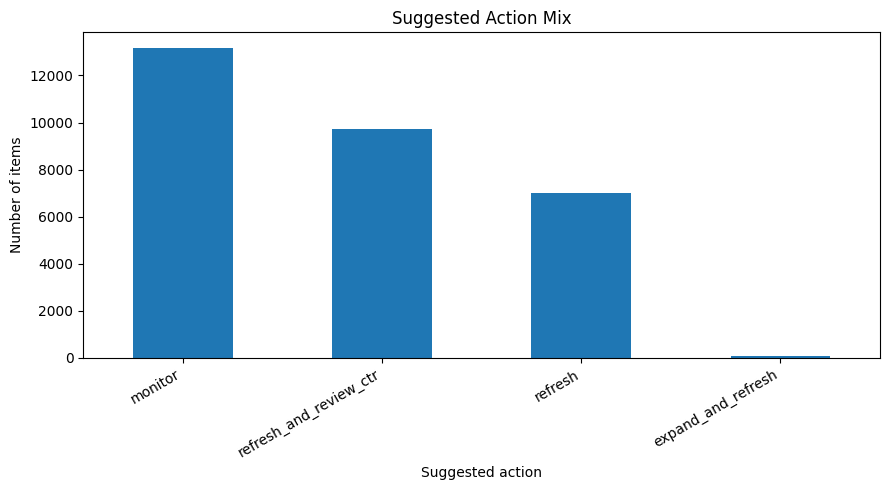

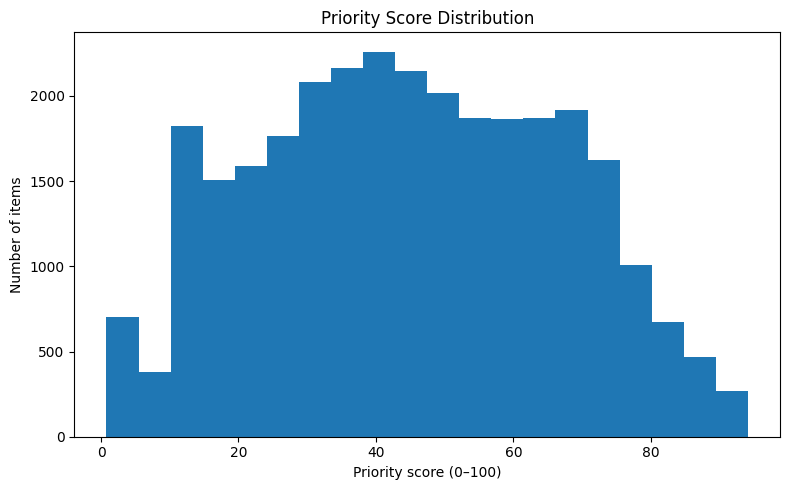

Saved files:
- /content/work/outputs/action_queue_for_paper.csv
- /content/work/outputs/action_playbook_summary.json
- /content/work/outputs/monitoring_triggers.csv
- /content/work/outputs/action_mix.png
- /content/work/outputs/priority_score_distribution.png

Queue preview:


,rank,content_id,priority_score,priority_band,suggested_action,reason_codes,impressions_90d,sessions_90d,avg_position,ctr,content_age_days,days_since_last_update,word_count,content_type,main_intent
0,1,content_9532f197bbc8,94.118885,high_review_priority,refresh,declining_with_demand|page_one_decay_risk|low_...,309192,1098,2.0,0.87,445,104,NaN,keyword article,informational
1,2,content_4d1fe5b32dc2,93.488901,high_review_priority,monitor,page_one_decay_risk|low_engagement_visible_page,97999,549,2.5,0.52,329,104,NaN,keyword article,transactional
2,3,content_07f2e7a6f38a,93.408003,high_review_priority,monitor,page_one_decay_risk|low_engagement_visible_page,101078,780,2.7,0.85,313,104,NaN,keyword article,transactional
3,4,content_e5ae436f9a16,93.360573,high_review_priority,refresh_and_review_ctr,page_one_decay_risk|low_ctr_visible_page|low_e...,117741,522,3.0,0.45,421,104,NaN,keyword article,commercial
4,5,content_3430a8b94511,93.355858,high_review_priority,refresh_and_review_ctr,page_one_decay_risk|low_ctr_visible_page|low_e...,152617,534,3.3,0.29,329,104,NaN,keyword article,transactional
5,6,content_cbd93118300b,93.326312,high_review_priority,refresh_and_review_ctr,declining_with_demand|page_one_decay_risk|low_...,145292,535,3.3,0.46,313,104,NaN,keyword article,transactional
6,7,content_9c195417f6ef,93.299127,high_review_priority,monitor,page_one_decay_risk|low_engagement_visible_page,79146,515,2.5,0.73,313,104,NaN,keyword article,transactional
7,8,content_ba2acb4ebd04,93.162259,high_review_priority,monitor,page_one_decay_risk|low_engagement_visible_page,142072,1147,3.6,0.83,362,104,NaN,keyword article,informational
8,9,content_79b25654070a,93.136289,high_review_priority,refresh_and_review_ctr,page_one_decay_risk|low_ctr_visible_page|low_e...,148737,619,3.7,0.48,257,104,NaN,keyword article,informational
9,10,content_adddad39251c,93.112369,high_review_priority,monitor,page_one_decay_risk|low_engagement_visible_page,129239,688,3.6,0.55,329,104,NaN,keyword article,transactional


In [9]:
import json
import matplotlib.pyplot as plt

# Find the repo root and create the requested output directory.
repo_root = next(
    (root for root in SEARCH_ROOTS if (root / "work").is_dir()),
    Path.cwd()
)
output_dir = repo_root / "work" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Export only fields needed for the playbook and paper.
# Never export client_id, trend_direction, or the target label.
allowed_export_columns = [
    "rank",
    "content_id",
    "priority_score",
    "priority_band",
    "suggested_action",
    "reason_codes",
    "impressions_90d",
    "sessions_90d",
    "avg_position",
    "ctr",
    "content_age_days",
    "days_since_last_update",
    "word_count",
    "content_type",
    "main_intent",
    "best_model_name",
]

export_columns = [c for c in allowed_export_columns if c in queue.columns]
export_queue = queue[export_columns].head(200).copy()

# Safety checks before writing.
forbidden_columns = {
    "client_id", "trend_direction", "trend_pct",
    "is_declining_label", "url", "page_url", "query", "keyword"
}
assert not (set(export_queue.columns) & forbidden_columns), (
    "Unsafe column found in export."
)
assert "content_id" in export_queue.columns
assert "reason_codes" in export_queue.columns

queue_path = output_dir / "action_queue_for_paper.csv"
export_queue.to_csv(queue_path, index=False)

# Summarize the complete queue, not just the top 200 exported rows.
action_counts = queue["suggested_action"].value_counts().to_dict()
band_counts = queue["priority_band"].value_counts().to_dict()

summary = {
    "queue_source": queue_source,
    "total_rows_ranked": int(len(queue)),
    "rows_exported": int(len(export_queue)),
    "score_scale": "0-100, normalized for presentation",
    "score_min": float(queue["priority_score"].min()) if len(queue) else None,
    "score_median": float(queue["priority_score"].median()) if len(queue) else None,
    "score_max": float(queue["priority_score"].max()) if len(queue) else None,
    "action_counts": {str(k): int(v) for k, v in action_counts.items()},
    "priority_band_counts": {str(k): int(v) for k, v in band_counts.items()},
    "intended_use": "Human review prioritization; not automatic publishing",
}

summary_path = output_dir / "action_playbook_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

monitor_path = output_dir / "monitoring_triggers.csv"
monitoring_plan.to_csv(monitor_path, index=False)

# Figure 1: suggested action mix across the full queue.
action_series = queue["suggested_action"].value_counts()
plt.figure(figsize=(9, 5))
action_series.plot(kind="bar")
plt.title("Suggested Action Mix")
plt.xlabel("Suggested action")
plt.ylabel("Number of items")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
action_chart_path = output_dir / "action_mix.png"
plt.savefig(action_chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# Figure 2: priority score distribution.
plt.figure(figsize=(8, 5))
plt.hist(queue["priority_score"].dropna(), bins=20)
plt.title("Priority Score Distribution")
plt.xlabel("Priority score (0–100)")
plt.ylabel("Number of items")
plt.tight_layout()
score_chart_path = output_dir / "priority_score_distribution.png"
plt.savefig(score_chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Saved files:")
for path in [
    queue_path, summary_path, monitor_path,
    action_chart_path, score_chart_path
]:
    print("-", path)

print("\nQueue preview:")
display(export_queue.head(10))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.